In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

2026-10-22 18:05:28.469075: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-22 18:05:28.830504: I tensorflow/core/util/util.cc:169] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-22 18:05:32.203042: I tensorflow/c/logging.cc:34] Successfully opened dynamic library libdirectml.d6f03b303ac3c4f2eeb8ca631688c9757b361310.so
2026-10-22 18:05:32.203330: I tensorflow/c/logging.cc:34] Successfully opened dynamic library libdxcore.so
2026-10-22 18:05:32.214804: I tensorflow/c/logging.cc:34] Successfully opened dynamic library libd

In [2]:
# Reproducibility
keras.utils.set_random_seed(42)

In [3]:
# 1. Load the dataset
dataset = load_breast_cancer()
X = dataset.data.astype("float32")
y = dataset.target.astype("float32")

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", dataset.target_names)

Feature shape: (569, 30)
Target shape: (569,)
Classes: ['malignant' 'benign']


In [4]:
# 2. Split into training, validation and test sets
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.20,
    random_state=42,
    stratify=y_trainval
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (364, 30)
Validation: (91, 30)
Test: (114, 30)


In [5]:
# 3. Build a classifier
def build_classifier(input_dim, architecture):
    normalizer = layers.Normalization()
    normalizer.adapt(X_train)

    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        normalizer
    ])

    if architecture == "small":
        model.add(layers.Dense(16, activation="relu"))
    elif architecture == "larger":
        model.add(layers.Dense(64, activation="relu"))
        model.add(layers.Dense(32, activation="relu"))

    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [6]:
# 4. Train and compare two architectures
architectures = ["small", "larger"]
classification_results = {}
classification_histories = {}
classification_models = {}

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

for architecture in architectures:
    keras.utils.set_random_seed(42)

    model = build_classifier(X_train.shape[1], architecture)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=32,
        callbacks=[early_stopping],
        verbose=0
    )

    # Evaluate once on the held-out test set
    probabilities = model.predict(X_test, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    results = {
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0)
    }

    classification_models[architecture] = model
    classification_histories[architecture] = history
    classification_results[architecture] = results

    print(f"\nArchitecture: {architecture}")
    print("Test metrics:", results)
    print("Confusion matrix:\n", confusion_matrix(y_test, predictions))
    print(classification_report(
        y_test,
        predictions,
        target_names=dataset.target_names,
        zero_division=0
    ))


2026-10-22 18:05:35.146783: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-22 18:05:35.164364: I tensorflow/c/logging.cc:34] DirectML: creating device on adapter 0 (Intel(R) Iris(R) Xe Graphics)
2026-10-22 18:05:35.346197: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-22 18:05:35.346326: W tensorflow/core/common_runtime/pluggable_device/pluggable_device_bfc_allocator.cc:28] Overriding allow_growth setting because force_memory_growth was requested by the device.
2026-10-22 18:05:35.346403: I tensorflow/core/common_runtime/pluggable_device/plug


Architecture: small
Test metrics: {'accuracy': 0.956140350877193, 'precision': 0.971830985915493, 'recall': 0.9583333333333334, 'f1': 0.965034965034965}
Confusion matrix:
 [[40  2]
 [ 3 69]]
              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        42
      benign       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



2026-10-22 18:05:51.436422: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:05:51.526991: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:05:53.681559: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:05:53.888909: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-22 18:05:53.889178: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 6941 MB memory) -> physical PluggableDevice (device: 0, name: DML, pci bus id: <undefined>)
2026-10-22 18:05:55.0


Architecture: larger
Test metrics: {'accuracy': 0.956140350877193, 'precision': 0.9855072463768116, 'recall': 0.9444444444444444, 'f1': 0.9645390070921985}
Confusion matrix:
 [[41  1]
 [ 4 68]]
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



2026-10-22 18:06:04.954938: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-22 18:06:04.982485: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-22 18:06:04.982552: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 6941 MB memory) -> physical PluggableDevice (device: 0, name: DML, pci bus id: <undefined>)
2026-10-22 18:06:04.985646: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-22 18:06:04.985710: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_fa

In [7]:
history = classification_histories["small"]

best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Best validation-loss epoch:", best_epoch)
print("Best validation loss:", min(history.history["val_loss"]))

Best validation-loss epoch: 72
Best validation loss: 0.07783803343772888


In [8]:
# 5. Compare architecture metrics
for architecture, results in classification_results.items():
    print(architecture, results)

small {'accuracy': 0.956140350877193, 'precision': 0.971830985915493, 'recall': 0.9583333333333334, 'f1': 0.965034965034965}
larger {'accuracy': 0.956140350877193, 'precision': 0.9855072463768116, 'recall': 0.9444444444444444, 'f1': 0.9645390070921985}


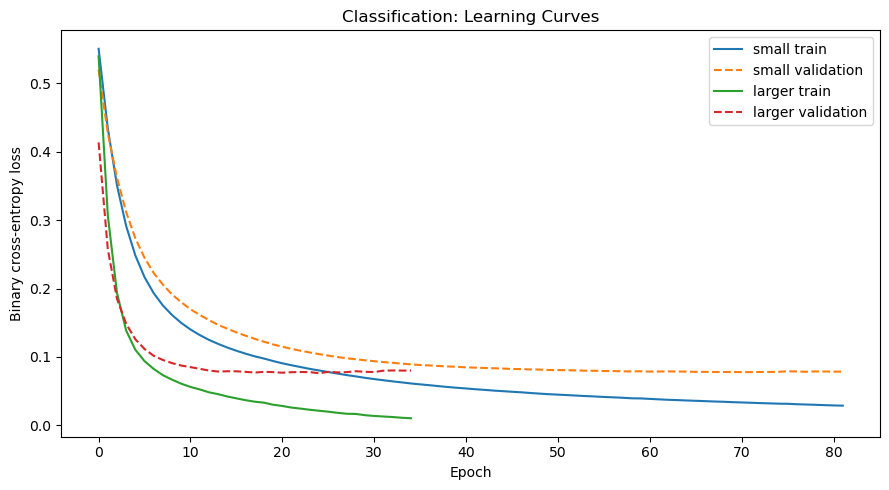

In [9]:
# 6. Plot training and validation loss
plt.figure(figsize=(9, 5))

for architecture, history in classification_histories.items():
    plt.plot(
        history.history["loss"],
        label=f"{architecture} train"
    )
    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=f"{architecture} validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Classification: Learning Curves")
plt.legend()
plt.tight_layout()
plt.show()